In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("transformed_retail_sales.csv")
print(df)

       Row ID         Order ID  Order Date   Ship Date       Ship Mode  \
0       42433     AG-2011-2040  2011-01-01  2011-01-06  Standard Class   
1       22253    IN-2011-47883  2011-01-01  2011-01-08  Standard Class   
2       48883     HU-2011-1220  2011-01-01  2011-01-05    Second Class   
3       11731  IT-2011-3647632  2011-01-01  2011-01-05    Second Class   
4       22255    IN-2011-47883  2011-01-01  2011-01-08  Standard Class   
...       ...              ...         ...         ...             ...   
51285   32593   CA-2014-115427  2014-12-31  2015-01-04  Standard Class   
51286   47594     MO-2014-2560  2014-12-31  2015-01-05  Standard Class   
51287    8857   MX-2014-110527  2014-12-31  2015-01-02    Second Class   
51288    6852   MX-2014-114783  2014-12-31  2015-01-06  Standard Class   
51289   36388   CA-2014-156720  2014-12-31  2015-01-04  Standard Class   

      Customer ID     Customer Name      Segment         City  \
0        TB-11280   Toby Braunhardt     Consum

Customer Revenue

In [ ]:
customer_sales = df.groupby("Customer ID")["Sales"].sum().sort_values(ascending=False)

print(customer_sales)

Customer ID
TA-21385    35668.12080
GT-14710    34471.89028
TC-20980    34218.26900
SM-20320    31125.29496
BW-11110    30613.61650
               ...     
MP-7470        58.11000
BD-1500        52.04700
RC-9825        37.44000
MG-7890        19.12800
ZC-11910        7.17300
Name: Sales, Length: 1590, dtype: float64


Top Customers

In [ ]:
#Top 10 customers
top_10_customers = customer_sales.head(10)

print("Top 10 Customers:",top_10_customers)


Top 10 Customers: Customer ID
TA-21385    35668.12080
GT-14710    34471.89028
TC-20980    34218.26900
SM-20320    31125.29496
BW-11110    30613.61650
HL-15040    29664.23058
SE-20110    29532.62502
PS-19045    29252.31940
RB-19360    29197.63460
ZC-21910    28472.81926
Name: Sales, dtype: float64


In [ ]:
#Top 20 customers
top_20_customers = customer_sales.head(20)

print("Top 20 Customers:", top_20_customers)


Top 20 Customers: Customer ID
TA-21385    35668.12080
GT-14710    34471.89028
TC-20980    34218.26900
SM-20320    31125.29496
BW-11110    30613.61650
HL-15040    29664.23058
SE-20110    29532.62502
PS-19045    29252.31940
RB-19360    29197.63460
ZC-21910    28472.81926
CC-12370    28229.85140
SP-20920    28124.21286
NF-18385    28044.35950
PF-19120    27993.04966
FH-14365    27649.32652
HM-14860    27434.16760
BE-11335    27158.01840
AF-10870    26487.25850
DR-12940    25641.46492
SC-20095    25602.61000
Name: Sales, dtype: float64


Average Customer Spending

In [ ]:
total_customer_sales = customer_sales.sum()

number_of_customers = customer_sales.count()

average_customer_spending = total_customer_sales / number_of_customers

print("Average Customer Spending:", average_customer_spending)

Average Customer Spending: 7951.259062817609


Repeat Customers

In [ ]:
orders_per_customer = df.groupby("Customer ID")["Order ID"].nunique()

repeat_customers = orders_per_customer[orders_per_customer > 1]

print("Repeat Customers:",repeat_customers)
print("Number of Repeat Customers:", len(repeat_customers))

Repeat Customers: Customer ID
AA-10315    19
AA-10375    23
AA-10480    20
AA-10645    36
AA-315       7
            ..
YS-11880     6
YS-21880    26
ZC-21910    37
ZD-11925     9
ZD-21925    20
Name: Order ID, Length: 1580, dtype: int64
Number of Repeat Customers: 1580


Customer Contribution


In [ ]:
total_sales = df["Sales"].sum()

customer_contribution = (customer_sales / total_sales) * 100

print("Customer Contribution:", customer_contribution)

Customer Contribution: Customer ID
TA-21385    0.282129
GT-14710    0.272667
TC-20980    0.270661
SM-20320    0.246196
BW-11110    0.242148
              ...   
MP-7470     0.000460
BD-1500     0.000412
RC-9825     0.000296
MG-7890     0.000151
ZC-11910    0.000057
Name: Sales, Length: 1590, dtype: float64


Customer Segments

In [ ]:
def customer_segment(sales):
    if sales >= 5000:
        return "High Value"
    elif sales >= 2000:
        return "Medium Value"
    else:
        return "Low Value"

customer_segments = customer_sales.apply(customer_segment)

print("Customer Segments:", customer_segments)


Customer Segments: Customer ID
TA-21385    High Value
GT-14710    High Value
TC-20980    High Value
SM-20320    High Value
BW-11110    High Value
               ...    
MP-7470      Low Value
BD-1500      Low Value
RC-9825      Low Value
MG-7890      Low Value
ZC-11910     Low Value
Name: Sales, Length: 1590, dtype: object


##Visualizations

Top 10 Customers

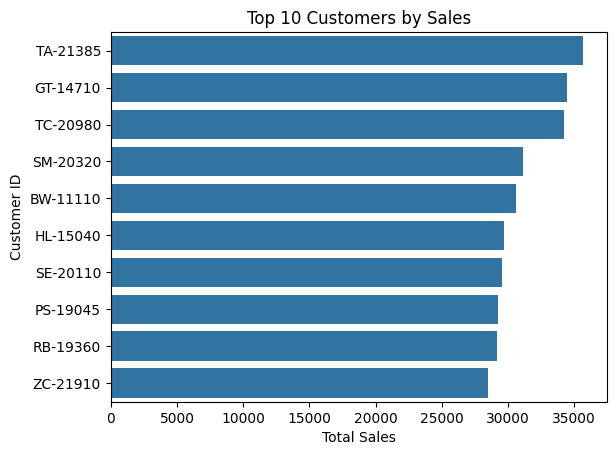

In [ ]:
sns.barplot(data=top_10_customers.reset_index(),x="Sales", y="Customer ID")
plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer ID")
plt.show()

This graph shows the ten customers who generate the highest total sales. It helps identify the company's most valuable customers based on revenue.

Customer Contribution

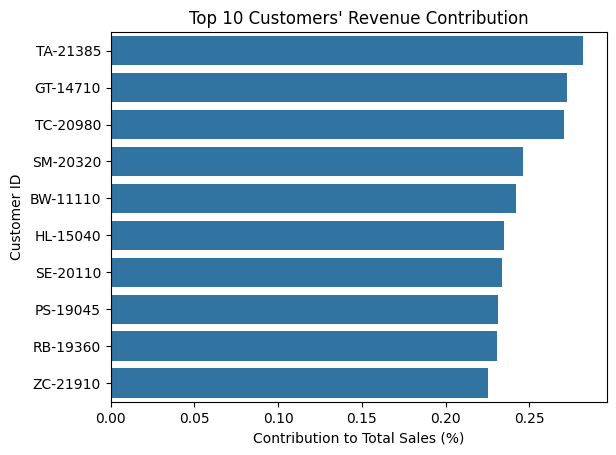

In [ ]:
contribution_df = customer_contribution.head(10).reset_index()
contribution_df.columns = ["Customer ID", "Contribution"]

sns.barplot(data=contribution_df, x="Contribution", y="Customer ID")

plt.title("Top 10 Customers' Revenue Contribution")
plt.xlabel("Contribution to Total Sales (%)")
plt.ylabel("Customer ID")
plt.show()

This graph shows the ten customers who generate the highest total sales. It helps identify the company's most valuable customers based on revenue.

Customer Segment Distribution

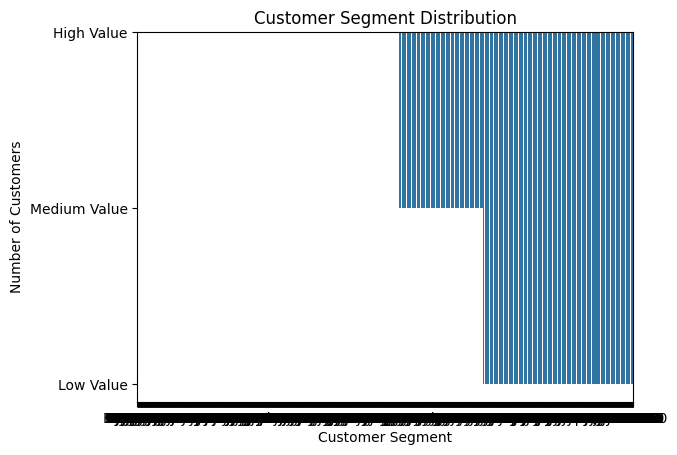

In [ ]:
segment_df = customer_segments.reset_index()

segment_df.columns = ["Customer Segment", "Number of Customers"]

sns.barplot(data=segment_df, x="Customer Segment", y="Number of Customers")

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.show()

This graph compares the number of High Value, Medium Value, and Low Value customers. It helps the company understand the composition of its customer base.

Repeat vs One-Time Customers

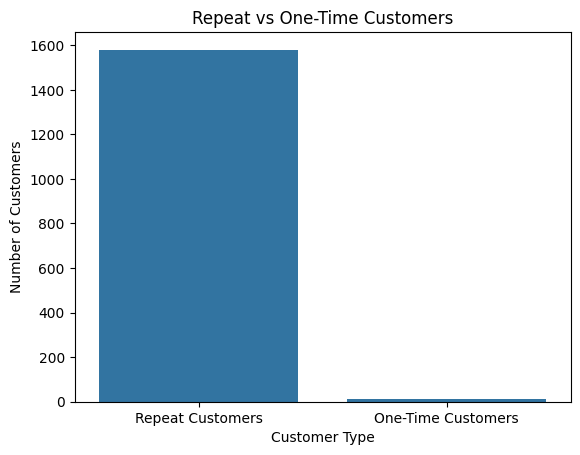

In [ ]:
orders_per_customer = df.groupby("Customer ID")["Order ID"].nunique()

repeat_customers = orders_per_customer[orders_per_customer > 1]

one_time_customers = orders_per_customer[orders_per_customer == 1]

customer_type_df = pd.DataFrame({
    "Customer Type": ["Repeat Customers", "One-Time Customers"],
    "Number of Customers": [
        len(repeat_customers),
        len(one_time_customers)
    ]
})

sns.barplot(data=customer_type_df, x="Customer Type", y="Number of Customers")

plt.title("Repeat vs One-Time Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.show()

This graph compares the number of repeat customers with one-time customers. It helps the company understand customer retention and identify opportunities to encourage customers to purchase again.